# Flowers102 Runner Artifact Sanity

**Objective.** Run the installed image runner from start to finish with eight images at `64 × 64` resolution.

**Success criteria.**

- Complete 10,000 optimizer updates without a non-finite loss.
- Replay five checkpoints with one fixed noise bank.
- Verify every required saved-run artifact.
- Display 64 final `x_1` samples in an `8 × 8` grid.

**Experiment.** Use eight Flowers102 training images at `64 × 64` resolution.

The notebook uses the term optimizer update because the runner samples shuffled batches continuously.

An epoch is not a stable unit when the training subset or batch size changes.


In [1]:
# Purpose: Import the required packages and define stable repository paths.
import json
import shlex
import shutil
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

# Locate the checkout without depending on the notebook launch directory.
REPO_ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "mem_param_src").is_dir()
)
sys.path.insert(0, str(REPO_ROOT))

from mem_param_src.runners.artifacts import (
    list_checkpoints,
    load_torch,
    read_json,
    validate_data_manifest,
)

DATA_ROOT = REPO_ROOT / "data"
CONFIG_PATH = REPO_ROOT / "configs" / "runners" / "flowers102_smoke.py"
OUTPUT_ROOT = REPO_ROOT / "outputs" / "sanity"

# Use one new directory because the runner rejects existing experiment output.
RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_DIR = OUTPUT_ROOT / f"flowers102_runner_64_n8_10k_{RUN_STAMP}"

# Use the installed console command to test the public runner interface.
RUNNER_PATH = shutil.which("mem-param-image-train")
assert RUNNER_PATH is not None
assert DATA_ROOT.is_dir()
assert CONFIG_PATH.is_file()
assert not RUN_DIR.exists()

print(f"repository: {REPO_ROOT}")
print(f"runner: {RUNNER_PATH}")
print(f"run directory: {RUN_DIR}")


repository: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean
runner: /Users/mohammadaljaff/miniforge3/envs/memcompgen/bin/mem-param-image-train
run directory: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/sanity/flowers102_runner_64_n8_10k_20260820T184554Z


In [2]:
# Purpose: Define one complete runner command with explicit experiment settings.
N_TRAIN = 8
IMAGE_SIZE = 64
N_TRAINING_STEPS = 10_000
CHECKPOINT_EVERY = 2_500
N_SAMPLES = 64
SAMPLING_STEPS = 50

# Keep the small tested UNet and increase only the data resolution and run length.
command = [
    RUNNER_PATH,
    "--config",
    str(CONFIG_PATH.relative_to(REPO_ROOT)),
    "--run-dir",
    str(RUN_DIR),
    "--device",
    "auto",
    "--evaluate-after-training",
    "--set",
    "study.name=flowers102_runner_artifact_sanity",
    "--set",
    "outputs.run_name=flowers102_runner_artifact_sanity",
    "--set",
    f"data.n_train={N_TRAIN}",
    "--set",
    f"data.n_test={N_SAMPLES}",
    "--set",
    f"data.image_size={IMAGE_SIZE}",
    "--set",
    f"data.resize_size={IMAGE_SIZE}",
    "--set",
    f"training.n_training_steps={N_TRAINING_STEPS}",
    "--set",
    f"training.batch_cap={N_TRAIN}",
    "--set",
    "training.ckpt_schedule=interval",
    "--set",
    f"training.ckpt_every={CHECKPOINT_EVERY}",
    "--set",
    "training.log_every=250",
    "--set",
    f"evaluation.n_samples={N_SAMPLES}",
    "--set",
    f"evaluation.sample_bank_size={N_SAMPLES}",
    "--set",
    "evaluation.batch_size=8",
    "--set",
    f"evaluation.chunk_size={N_SAMPLES}",
    "--set",
    "evaluation.f_mem_threshold=0.3",
    "--set",
    f"sampling.n_steps={SAMPLING_STEPS}",
    "--set",
    "sampling.output=x_1",
]

print(shlex.join(command))


/Users/mohammadaljaff/miniforge3/envs/memcompgen/bin/mem-param-image-train --config configs/runners/flowers102_smoke.py --run-dir /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/sanity/flowers102_runner_64_n8_10k_20260820T184554Z --device auto --evaluate-after-training --set study.name=flowers102_runner_artifact_sanity --set outputs.run_name=flowers102_runner_artifact_sanity --set data.n_train=8 --set data.n_test=64 --set data.image_size=64 --set data.resize_size=64 --set training.n_training_steps=10000 --set training.batch_cap=8 --set training.ckpt_schedule=interval --set training.ckpt_every=2500 --set training.log_every=250 --set evaluation.n_samples=64 --set evaluation.sample_bank_size=64 --set evaluation.batch_size=8 --set evaluation.chunk_size=64 --set evaluation.f_mem_threshold=0.3 --set sampling.n_steps=50 --set sampling.output=x_1


In [3]:
# Purpose: Run training and checkpoint evaluation in one blocking process.
start_seconds = time.perf_counter()

# This call returns only after training and every checkpoint evaluation finish.
completed = subprocess.run(command, cwd=REPO_ROOT, check=True)
elapsed_minutes = (time.perf_counter() - start_seconds) / 60.0

assert completed.returncode == 0
print(f"runner return code: {completed.returncode}")
print(f"total runtime: {elapsed_minutes:.2f} minutes")


step 1/10000 loss=1.338079


step 250/10000 loss=0.184360


step 500/10000 loss=0.245293


step 750/10000 loss=0.131260


step 1000/10000 loss=0.127600


step 1250/10000 loss=0.180153


... (33 outputs left out)

step 9750/10000 loss=0.097041


step 10000/10000 loss=0.030367


/Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/sanity/flowers102_runner_64_n8_10k_20260820T184554Z


runner return code: 0
total runtime: 12.05 minutes


In [4]:
# Purpose: Verify the required saved-run files and display the artifact tree.
required_paths = [
    "run.json",
    "config.json",
    "data_bundle.pt",
    "data_manifest.json",
    "z_init.pt",
    "train_history.json",
    "evaluations/default/settings.json",
    "evaluations/default/checkpoint_metrics.json",
    "evaluations/default/final_samples_x_1.pt",
]

missing_paths = [name for name in required_paths if not (RUN_DIR / name).is_file()]
assert not missing_paths, missing_paths

# Keep the listing short while showing every file created by this run.
artifact_files = sorted(
    path.relative_to(RUN_DIR).as_posix()
    for path in RUN_DIR.rglob("*")
    if path.is_file()
)
for artifact_file in artifact_files:
    print(artifact_file)


checkpoints/step_000000.pt
checkpoints/step_002500.pt
checkpoints/step_005000.pt
checkpoints/step_007500.pt
checkpoints/step_010000.pt
config.json
data_bundle.pt
data_manifest.json
evaluations/default/checkpoint_metrics.json
evaluations/default/final_samples_x_1.pt
evaluations/default/settings.json
run.json
train_history.json
z_init.pt


In [5]:
# Purpose: Validate the resolved configuration and final run state.
run_record = read_json(RUN_DIR / "run.json")
saved_config = read_json(RUN_DIR / "config.json")

# Include step zero and the final step in every checkpoint schedule.
expected_checkpoint_steps = list(
    range(0, N_TRAINING_STEPS + 1, CHECKPOINT_EVERY)
)
if expected_checkpoint_steps[-1] != N_TRAINING_STEPS:
    expected_checkpoint_steps.append(N_TRAINING_STEPS)

assert run_record["artifact_format_version"] == 2
assert run_record["state"] == "evaluated"
assert run_record["final_step"] == N_TRAINING_STEPS
assert run_record["n_train"] == N_TRAIN
assert run_record["n_reference"] == N_SAMPLES
assert run_record["last_evaluation"] == "default"

assert saved_config["data"]["image_size"] == IMAGE_SIZE
assert saved_config["data"]["n_train"] == N_TRAIN
assert saved_config["training"]["batch_size"] == N_TRAIN
assert saved_config["training"]["resolved_ckpt_steps"] == expected_checkpoint_steps
assert saved_config["evaluation"]["n_samples"] == N_SAMPLES
assert saved_config["evaluation"]["f_mem_threshold"] == 0.3
assert saved_config["sampling"]["output"] == "x_1"

metadata_summary = {
    "state": run_record["state"],
    "device": run_record["resolved_device"],
    "parameters": run_record["parameter_count"],
    "optimizer_updates": run_record["final_step"],
    "checkpoint_steps": expected_checkpoint_steps,
}
metadata_summary


{'state': 'evaluated',
 'device': 'mps',
 'parameters': 669251,
 'optimizer_updates': 10000,
 'checkpoint_steps': [0, 2500, 5000, 7500, 10000]}

In [6]:
# Purpose: Validate exact saved tensors, sample identities, and artifact hashes.
bundle = load_torch(RUN_DIR / "data_bundle.pt")
z_init = load_torch(RUN_DIR / "z_init.pt")

# Recompute all stored hashes to detect an incomplete or changed artifact.
manifest = validate_data_manifest(
    RUN_DIR,
    bundle,
    run_kind="image",
    verify_hashes=True,
)

expected_train_shape = (N_TRAIN, 3, IMAGE_SIZE, IMAGE_SIZE)
expected_sample_shape = (N_SAMPLES, 3, IMAGE_SIZE, IMAGE_SIZE)

assert tuple(bundle["train"].shape) == expected_train_shape
assert tuple(bundle["reference"].shape) == expected_sample_shape
assert tuple(z_init.shape) == expected_sample_shape
assert torch.isfinite(bundle["train"]).all()
assert torch.isfinite(bundle["reference"]).all()
assert torch.isfinite(z_init).all()

assert len(bundle["train_sample_ids"]) == N_TRAIN
assert len(set(bundle["train_sample_ids"])) == N_TRAIN
assert len(bundle["reference_sample_ids"]) == N_SAMPLES
assert bundle["train_source_id"] != bundle["reference_source_id"]
assert manifest["partitions"]["train"]["sample_ids"] == bundle["train_sample_ids"]

tensor_summary = {
    "train_shape": tuple(bundle["train"].shape),
    "reference_shape": tuple(bundle["reference"].shape),
    "z_init_shape": tuple(z_init.shape),
    "train_source": bundle["train_source_id"],
    "reference_source": bundle["reference_source_id"],
    "train_sample_ids": bundle["train_sample_ids"],
    "bundle_sha256": manifest["bundle"]["sha256"],
}
tensor_summary


{'train_shape': (8, 3, 64, 64),
 'reference_shape': (64, 3, 64, 64),
 'z_init_shape': (64, 3, 64, 64),
 'train_source': 'torchvision_flowers102:train',
 'reference_source': 'torchvision_flowers102:val',
 'train_sample_ids': [315, 960, 795, 14, 487, 177, 281, 343],
 'bundle_sha256': '9dabe81c86becce68dd8c8b06bfa8189137aeea32f75e9491e42e25ce20b8e53'}

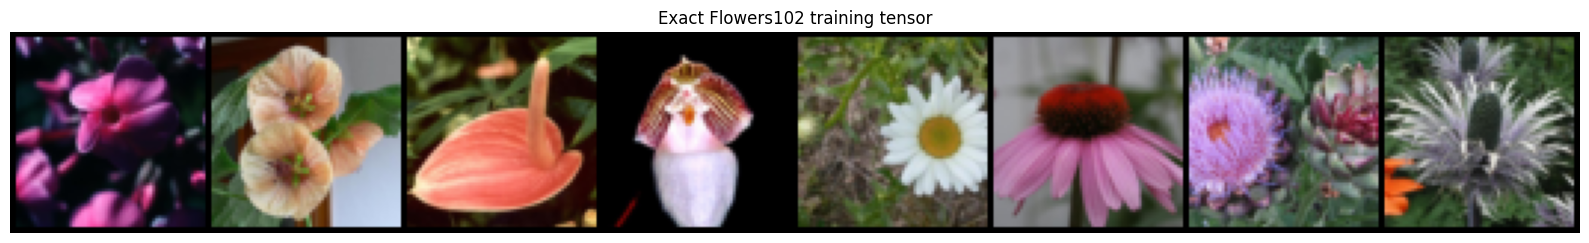

In [7]:
# Purpose: Display the exact eight images used by the optimizer.
# Convert only the display values from [-1, 1] to [0, 1].
training_display = bundle["train"].add(1.0).div(2.0).clamp(0.0, 1.0)
training_grid = make_grid(training_display, nrow=N_TRAIN, padding=2)

figure, axis = plt.subplots(figsize=(16, 2.5))
axis.imshow(training_grid.permute(1, 2, 0))
axis.set_title("Exact Flowers102 training tensor")
axis.axis("off")
figure.tight_layout()
plt.show()


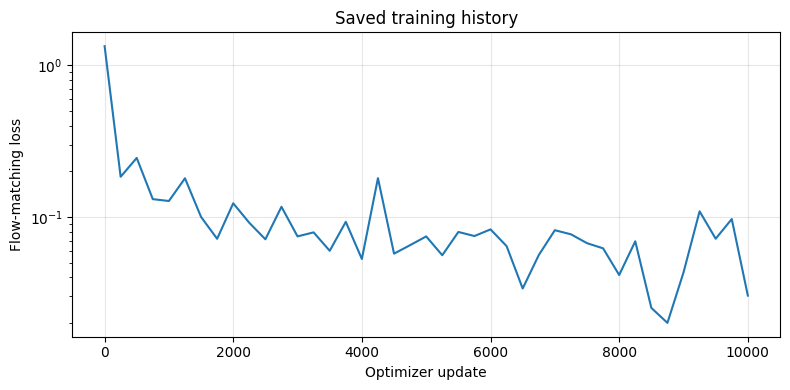

history records: 41
first loss: 1.338079
final loss: 0.030367
checkpoint steps: [0, 2500, 5000, 7500, 10000]


In [8]:
# Purpose: Validate saved checkpoints and inspect the training-loss trajectory.
history = read_json(RUN_DIR / "train_history.json")
checkpoint_entries = list_checkpoints(RUN_DIR)
checkpoint_steps = [step for step, _ in checkpoint_entries]

assert checkpoint_steps == expected_checkpoint_steps
assert history[0]["step"] == 1
assert history[-1]["step"] == N_TRAINING_STEPS
assert all(torch.isfinite(torch.tensor(item["loss"])) for item in history)

loss_steps = [item["step"] for item in history]
loss_values = [item["loss"] for item in history]

figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(loss_steps, loss_values, linewidth=1.5)
axis.set_yscale("log")
axis.set_xlabel("Optimizer update")
axis.set_ylabel("Flow-matching loss")
axis.set_title("Saved training history")
axis.grid(alpha=0.3)
figure.tight_layout()
plt.show()

print(f"history records: {len(history)}")
print(f"first loss: {loss_values[0]:.6f}")
print(f"final loss: {loss_values[-1]:.6f}")
print(f"checkpoint steps: {checkpoint_steps}")


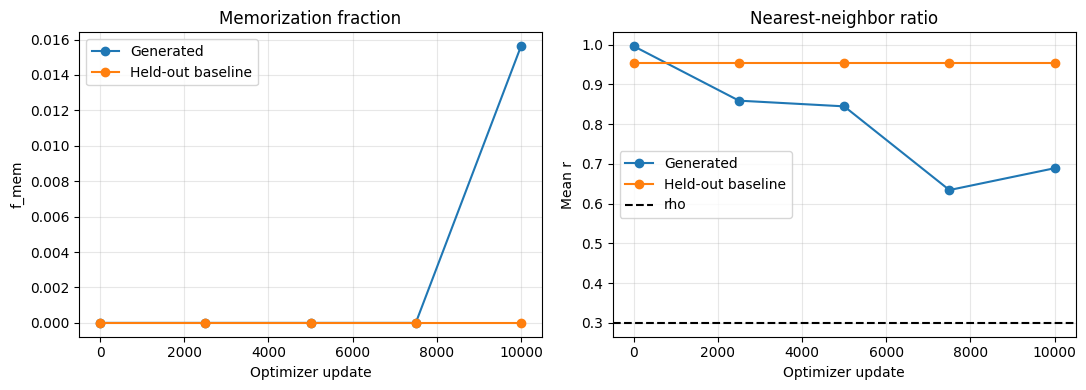

[
  {
    "step": 0,
    "f_mem": 0.0,
    "baseline_f_mem": 0.0,
    "mean_r": 0.9958486557006836
  },
  {
    "step": 2500,
    "f_mem": 0.0,
    "baseline_f_mem": 0.0,
    "mean_r": 0.8588396310806274
  },
  {
    "step": 5000,
    "f_mem": 0.0,
    "baseline_f_mem": 0.0,
    "mean_r": 0.8445050716400146
  },
  {
    "step": 7500,
    "f_mem": 0.0,
    "baseline_f_mem": 0.0,
    "mean_r": 0.6340422034263611
  },
  {
    "step": 10000,
    "f_mem": 0.015625,
    "baseline_f_mem": 0.0,
    "mean_r": 0.6889499425888062
  }
]


In [9]:
# Purpose: Validate and plot the checkpoint-level memorization metrics.
metrics = read_json(
    RUN_DIR / "evaluations" / "default" / "checkpoint_metrics.json"
)
metric_steps = [record["step"] for record in metrics]

assert metric_steps == expected_checkpoint_steps
assert all(record["sampling_output"] == "x_1" for record in metrics)
assert all(record["rho"] == 0.3 for record in metrics)
assert all(0.0 <= record["f_mem"] <= 1.0 for record in metrics)
assert all(0.0 <= record["baseline_f_mem"] <= 1.0 for record in metrics)

figure, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    metric_steps,
    [record["f_mem"] for record in metrics],
    marker="o",
    label="Generated",
)
axes[0].plot(
    metric_steps,
    [record["baseline_f_mem"] for record in metrics],
    marker="o",
    label="Held-out baseline",
)
axes[0].set_xlabel("Optimizer update")
axes[0].set_ylabel("f_mem")
axes[0].set_title("Memorization fraction")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    metric_steps,
    [record["mean_r"] for record in metrics],
    marker="o",
    label="Generated",
)
axes[1].plot(
    metric_steps,
    [record["baseline_mean_r"] for record in metrics],
    marker="o",
    label="Held-out baseline",
)
axes[1].axhline(metrics[0]["rho"], color="black", linestyle="--", label="rho")
axes[1].set_xlabel("Optimizer update")
axes[1].set_ylabel("Mean r")
axes[1].set_title("Nearest-neighbor ratio")
axes[1].legend()
axes[1].grid(alpha=0.3)

figure.tight_layout()
plt.show()

metric_rows = [
    {
        "step": record["step"],
        "f_mem": record["f_mem"],
        "baseline_f_mem": record["baseline_f_mem"],
        "mean_r": record["mean_r"],
    }
    for record in metrics
]
print(json.dumps(metric_rows, indent=2))


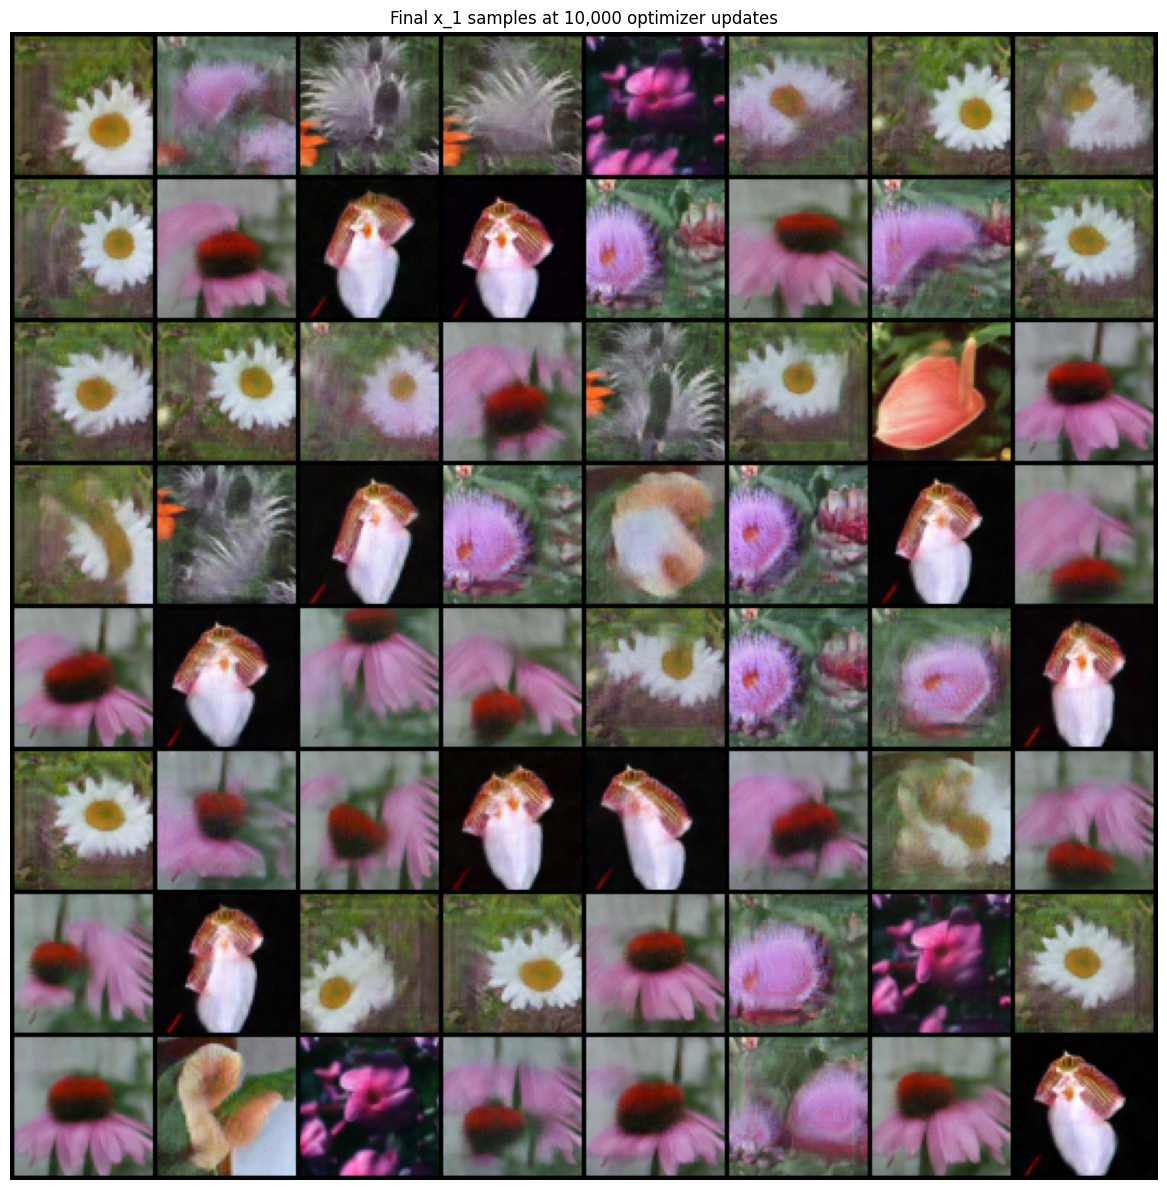

saved sample shape: (64, 3, 64, 64)
saved sample range: [-1.115, 1.126]


In [10]:
# Purpose: Load the final sample tensor and display one 8 by 8 grid.
sample_path = RUN_DIR / "evaluations" / "default" / "final_samples_x_1.pt"
samples = load_torch(sample_path)

assert tuple(samples.shape) == expected_sample_shape
assert torch.isfinite(samples).all()

# Clamp only the display values. Keep the saved sample tensor unchanged.
sample_display = samples.add(1.0).div(2.0).clamp(0.0, 1.0)
sample_grid = make_grid(sample_display, nrow=8, padding=2)

figure, axis = plt.subplots(figsize=(12, 12))
axis.imshow(sample_grid.permute(1, 2, 0))
axis.set_title("Final x_1 samples at 10,000 optimizer updates")
axis.axis("off")
figure.tight_layout()
plt.show()

print(f"saved sample shape: {tuple(samples.shape)}")
print(f"saved sample range: [{float(samples.min()):.3f}, {float(samples.max()):.3f}]")


In [11]:
# Purpose: Collect the final integration evidence in one compact record.
final_evidence = {
    "runner_return_code": completed.returncode,
    "run_state": run_record["state"],
    "runtime_minutes": elapsed_minutes,
    "optimizer_updates": N_TRAINING_STEPS,
    "training_examples": N_TRAIN,
    "image_shape": expected_train_shape[1:],
    "checkpoint_count": len(checkpoint_entries),
    "metric_record_count": len(metrics),
    "sample_shape": tuple(samples.shape),
    "samples_finite": bool(torch.isfinite(samples).all()),
    "final_f_mem": metrics[-1]["f_mem"],
    "final_mean_r": metrics[-1]["mean_r"],
}

assert final_evidence["checkpoint_count"] == len(expected_checkpoint_steps)
assert final_evidence["metric_record_count"] == len(expected_checkpoint_steps)
assert final_evidence["samples_finite"]

final_evidence


{'runner_return_code': 0,
 'run_state': 'evaluated',
 'runtime_minutes': 12.051720068751214,
 'optimizer_updates': 10000,
 'training_examples': 8,
 'image_shape': (3, 64, 64),
 'checkpoint_count': 5,
 'metric_record_count': 5,
 'sample_shape': (64, 3, 64, 64),
 'samples_finite': True,
 'final_f_mem': 0.015625,
 'final_mean_r': 0.6889499425888062}